# Customer Lapse Prediction

**Goal:** predict whether a customer will make no purchase in the next 90 days (lapse = 1). Comparing Logistic Regression, Random Forest, Gradient Boosting, and a neural-network MLP, then logging experiments with MLflow, explaining the selected model with SHAP, and exporting customer-level risk predictions.

In [11]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)
import joblib
import mlflow
import mlflow.sklearn

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")
RANDOM_SEED = 42

from pathlib import Path

BASE_DIR = Path(r"C:\Users\kholi\SIC-Graduation-project-")
DATA_DIR = BASE_DIR / "retail_outputs"
TRAIN_FILE = DATA_DIR / "lapse_train_v1.csv"
VALID_FILE = DATA_DIR / "lapse_validation_v1.csv"
TEST_FILE = DATA_DIR / "lapse_test_v1.csv"
DICTIONARY_FILE = DATA_DIR / "feature_dictionary.csv"
OUTPUT_DIR = BASE_DIR / "customer_lapse_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Train file exists:", TRAIN_FILE.exists())
print("Validation file exists:", VALID_FILE.exists())
print("Test file exists:", TEST_FILE.exists())

Train file exists: True
Validation file exists: True
Test file exists: True


## 1. Load files and check the target

In [13]:
ID_DTYPES = {"customer_id": "string"}
train_df = pd.read_csv(TRAIN_FILE, dtype=ID_DTYPES)
valid_df = pd.read_csv(VALID_FILE, dtype=ID_DTYPES)
test_df = pd.read_csv(TEST_FILE, dtype=ID_DTYPES)

for name, frame in [("Train", train_df), ("Validation", valid_df), ("Test", test_df)]:
    print(f"\n{name}: {frame.shape}")
    print("Snapshot dates:", sorted(frame["snapshot_date"].dropna().astype(str).unique()))
    print("Lapse rate:", round(frame["lapse"].mean(), 4))
    display(frame.head(3))


Train: (14734, 21)
Snapshot dates: ['2010-06-01', '2010-09-01', '2010-12-01', '2011-03-01']
Lapse rate: 0.5759


,customer_id,snapshot_date,recency_days,frequency_orders,monetary,average_order_value,average_basket_quantity,distinct_products,tenure_days,average_days_between_orders,orders_last_30d,orders_last_90d,orders_last_180d,spend_last_30d,spend_last_90d,spend_last_180d,cancellation_count,cancellation_value,cancellation_rate,country,lapse
0,12346,2010-06-01,90,1,27.05,27.05,5.0,5,0,NaN,0,0,1,0.00,0.00,27.05,0,0.00,0.0,United Kingdom,0
1,12349,2010-06-01,32,1,1068.52,1068.52,473.0,46,0,NaN,0,1,1,0.00,1068.52,1068.52,5,24.15,0.5,Italy,1
2,12355,2010-06-01,10,1,488.21,488.21,303.0,22,0,NaN,1,1,1,488.21,488.21,488.21,0,0.00,0.0,Bahrain,1



Validation: (4908, 21)
Snapshot dates: ['2011-06-01']
Lapse rate: 0.6705


,customer_id,snapshot_date,recency_days,frequency_orders,monetary,average_order_value,average_basket_quantity,distinct_products,tenure_days,average_days_between_orders,orders_last_30d,orders_last_90d,orders_last_180d,spend_last_30d,spend_last_90d,spend_last_180d,cancellation_count,cancellation_value,cancellation_rate,country,lapse
0,12346,2011-06-01,337,2,169.36,84.68,12.0,24,118,118.031250,0,0,0,0.0,0.00,0.00,0,0.0,0.0,United Kingdom,1
1,12347,2011-06-01,54,4,2434.96,608.74,406.5,90,157,52.616435,0,1,3,0.0,636.25,1823.43,0,0.0,0.0,Iceland,0
2,12348,2011-06-01,56,4,1388.40,347.10,622.0,24,189,63.275000,0,1,3,0.0,327.00,1167.24,0,0.0,0.0,Finland,1



Test: (5224, 21)
Snapshot dates: ['2011-09-01']
Lapse rate: 0.572


,customer_id,snapshot_date,recency_days,frequency_orders,monetary,average_order_value,average_basket_quantity,distinct_products,tenure_days,average_days_between_orders,orders_last_30d,orders_last_90d,orders_last_180d,spend_last_30d,spend_last_90d,spend_last_180d,cancellation_count,cancellation_value,cancellation_rate,country,lapse
0,12346,2011-09-01,429,2,169.36,84.680,12.000000,24,118,118.031250,0,0,0,0.00,0.00,0.00,0,0.0,0.0,United Kingdom,1
1,12347,2011-09-01,29,6,3402.39,567.065,349.833333,107,274,54.953889,1,2,3,584.91,967.43,1603.68,0,0.0,0.0,Iceland,0
2,12348,2011-09-01,148,4,1388.40,347.100,622.000000,24,189,63.275000,0,0,1,0.00,0.00,327.00,0,0.0,0.0,Finland,0


In [14]:
required_columns = {"customer_id", "snapshot_date", "lapse", "country"}
for split_name, frame in [("train", train_df), ("validation", valid_df), ("test", test_df)]:
    missing = required_columns - set(frame.columns)
    if missing:
        raise ValueError(f"{split_name} is missing required columns: {missing}")
    if frame["lapse"].isna().any():
        raise ValueError(f"{split_name} contains missing target labels")
    if not set(frame["lapse"].unique()).issubset({0, 1}):
        raise ValueError(f"{split_name}: lapse must be binary 0/1")

train_features = set(train_df.columns) - {"lapse"}
valid_features = set(valid_df.columns) - {"lapse"}
test_features = set(test_df.columns) - {"lapse"}
if train_features != valid_features or train_features != test_features:
    raise ValueError("Train/validation/test columns differ.")

if DICTIONARY_FILE.exists():
    feature_dictionary = pd.read_csv(DICTIONARY_FILE)
    display(feature_dictionary.head(30))
else:
    print("feature_dictionary.csv not found; continuing without displaying definitions.")

,Feature,Definition,Type,Notes
0,customer_id,Customer identifier,String,"Key, not a numeric predictor"
1,snapshot_date,Date features are calculated,Date,Features use earlier transactions
2,recency_days,Days since last purchase,Integer,Lower means more recent activity
3,frequency_orders,Distinct historical purchase invoices,Integer,Historical order frequency
4,monetary,Sum of historical line totals,Numeric,"Gross value, not profit"
5,average_order_value,Monetary divided by invoice count,Numeric,Historical average
6,average_basket_quantity,Quantity divided by invoice count,Numeric,Historical average units
7,distinct_products,Distinct historical stock codes,Integer,Historical product variety
8,tenure_days,First-to-last historical purchase span,Integer,Limited by dataset start
9,average_days_between_orders,Mean gap between historical orders,Numeric,Missing for single-order customers


## 2. Define features

In [15]:
TARGET = "lapse"
EXCLUDED_COLUMNS = ["customer_id", "snapshot_date", TARGET]
FEATURE_COLUMNS = [col for col in train_df.columns if col not in EXCLUDED_COLUMNS]

X_train = train_df[FEATURE_COLUMNS].copy()
y_train = train_df[TARGET].astype(int).copy()
X_valid = valid_df[FEATURE_COLUMNS].copy()
y_valid = valid_df[TARGET].astype(int).copy()
X_test = test_df[FEATURE_COLUMNS].copy()
y_test = test_df[TARGET].astype(int).copy()

categorical_features = X_train.select_dtypes(include=["object", "category", "string"]).columns.tolist()
numeric_features = [col for col in FEATURE_COLUMNS if col not in categorical_features]

print("Feature columns:", FEATURE_COLUMNS)
print("Numeric:", numeric_features)
print("Categorical:", categorical_features)
print("Excluded from model inputs:", EXCLUDED_COLUMNS)

try:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    one_hot = OneHotEncoder(handle_unknown="ignore", sparse=False)

def make_preprocessor():
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

    numeric_preprocessor = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_preprocessor = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder)
    ])
    return ColumnTransformer(transformers=[
        ("numeric", numeric_preprocessor, numeric_features),
        ("categorical", categorical_preprocessor, categorical_features)
    ], remainder="drop", verbose_feature_names_out=False)

print("Training rows:", len(X_train), "Validation rows:", len(X_valid), "Test rows:", len(X_test))

Feature columns: ['recency_days', 'frequency_orders', 'monetary', 'average_order_value', 'average_basket_quantity', 'distinct_products', 'tenure_days', 'average_days_between_orders', 'orders_last_30d', 'orders_last_90d', 'orders_last_180d', 'spend_last_30d', 'spend_last_90d', 'spend_last_180d', 'cancellation_count', 'cancellation_value', 'cancellation_rate', 'country']
Numeric: ['recency_days', 'frequency_orders', 'monetary', 'average_order_value', 'average_basket_quantity', 'distinct_products', 'tenure_days', 'average_days_between_orders', 'orders_last_30d', 'orders_last_90d', 'orders_last_180d', 'spend_last_30d', 'spend_last_90d', 'spend_last_180d', 'cancellation_count', 'cancellation_value', 'cancellation_rate']
Categorical: ['country']
Excluded from model inputs: ['customer_id', 'snapshot_date', 'lapse']
Training rows: 14734 Validation rows: 4908 Test rows: 5224


## 3. Evaluation helper

In [16]:
def get_positive_probability(model, X):
    """Return probability for class 1 (lapse)."""
    return model.predict_proba(X)[:, 1]


def evaluate_model(model, X, y, threshold=0.50):
    probabilities = get_positive_probability(model, X)
    predictions = (probabilities >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, predictions),
        "precision": precision_score(y, predictions, zero_division=0),
        "recall": recall_score(y, predictions, zero_division=0),
        "f1": f1_score(y, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y, probabilities),
        "threshold": threshold,
    }


def plot_confusion(y_true, probabilities, threshold=0.50, title="Confusion Matrix"):
    predictions = (probabilities >= threshold).astype(int)
    cm = confusion_matrix(y_true, predictions, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["Predicted active", "Predicted lapse"],
                yticklabels=["Actual active", "Actual lapse"])
    plt.title(title)
    plt.xlabel("Prediction")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()
    print(classification_report(y_true, predictions, target_names=["Active (0)", "Lapse (1)"], zero_division=0))

## 4. Train and compare ML + Deep Learning models with MLflow

In [17]:
mlflow.set_experiment("RetainRecommend_Customer_Lapse_Prediction")

model_configs = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_SEED
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_SEED
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=3, random_state=RANDOM_SEED
    ),
    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
        alpha=0.001, learning_rate_init=0.001, max_iter=250,
        early_stopping=True, validation_fraction=0.1, random_state=RANDOM_SEED
    ),
}

fitted_models = {}
validation_results = []

for model_name, estimator in model_configs.items():
    print(f"Training: {model_name}")
    pipeline = Pipeline(steps=[("preprocessor", make_preprocessor()), ("model", estimator)])

    with mlflow.start_run(run_name=model_name):
        pipeline.fit(X_train, y_train)
        metrics = evaluate_model(pipeline, X_valid, y_valid, threshold=0.50)

        mlflow.log_param("model_name", model_name)
        mlflow.log_param("feature_count_before_encoding", len(FEATURE_COLUMNS))
        mlflow.log_param("threshold", 0.50)
        mlflow.log_param("train_rows", len(X_train))
        mlflow.log_param("validation_rows", len(X_valid))
        mlflow.log_metrics({key: float(value) for key, value in metrics.items()})
        mlflow.set_tag("target", "lapse: no purchase in next 90 days")
        mlflow.set_tag("split_policy", "predefined chronological splits; no shuffle")
        mlflow.sklearn.log_model(pipeline, artifact_path="model", serialization_format="cloudpickle")

    fitted_models[model_name] = pipeline
    validation_results.append({"model": model_name, **metrics})

validation_results_df = (pd.DataFrame(validation_results).sort_values("roc_auc", ascending=False).reset_index(drop=True))
display(validation_results_df)
validation_results_df.to_csv(OUTPUT_DIR / "validation_model_comparison.csv", index=False)
print(
    "Saved validation comparison to:",
    OUTPUT_DIR / "validation_model_comparison.csv"
)

2026/10/26 18:43:53 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/26 18:43:54 INFO mlflow.store.db.utils: Updating database tables
2026/10/26 18:43:55 INFO mlflow.tracking.fluent: Experiment with name 'RetainRecommend_Customer_Lapse_Prediction' does not exist. Creating a new experiment.


Training: Logistic Regression


2026/10/26 18:43:56 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 18:43:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Training: Random Forest


2026/10/26 18:44:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 18:44:14 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


...

2026/10/26 18:44:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 18:44:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Training: MLP Neural Network


2026/10/26 18:44:28 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/26 18:44:28 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


,model,accuracy,precision,recall,f1,roc_auc,threshold
0,MLP Neural Network,0.779544,0.794455,0.905500,0.846350,0.820087,0.5
1,Gradient Boosting,0.783822,0.795443,0.912185,0.849823,0.819249,0.5
2,Logistic Regression,0.767930,0.832304,0.818900,0.825548,0.816659,0.5
3,Random Forest,0.778932,0.807071,0.880887,0.842365,0.808211,0.5


Saved validation comparison to: C:\Users\kholi\SIC-Graduation-project-\customer_lapse_outputs\validation_model_comparison.csv


## 5. Select the model using validation ROC-AUC

Selected model: MLP Neural Network
Validation metrics:
model        MLP Neural Network
accuracy               0.779544
precision              0.794455
recall                   0.9055
f1                      0.84635
roc_auc                0.820087
threshold                   0.5
dtype: object


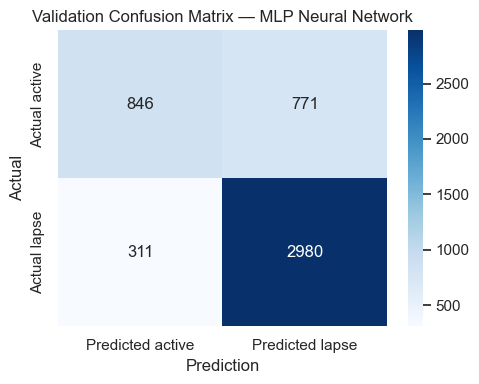

              precision    recall  f1-score   support

  Active (0)       0.73      0.52      0.61      1617
   Lapse (1)       0.79      0.91      0.85      3291

    accuracy                           0.78      4908
   macro avg       0.76      0.71      0.73      4908
weighted avg       0.77      0.78      0.77      4908



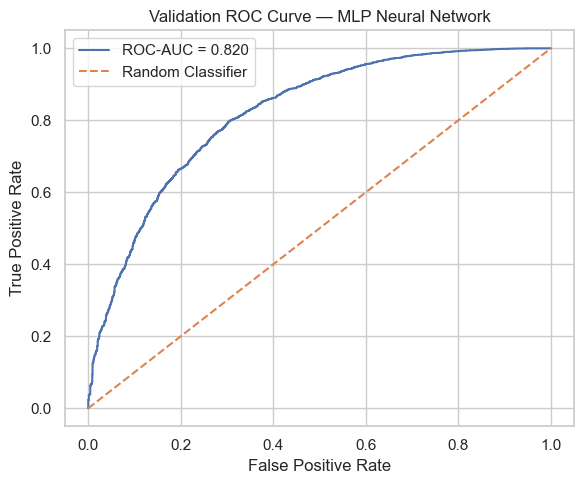

In [18]:
best_model_name = validation_results_df.iloc[0]["model"]
best_model = fitted_models[best_model_name]
best_validation_metrics = validation_results_df.iloc[0].to_dict()

print("Selected model:", best_model_name)
print("Validation metrics:")
print(pd.Series(best_validation_metrics))

valid_probabilities = get_positive_probability(best_model, X_valid)
plot_confusion(y_valid, valid_probabilities, threshold=0.50,
               title=f"Validation Confusion Matrix — {best_model_name}")

fpr, tpr, thresholds = roc_curve( y_valid, valid_probabilities )
plt.figure(figsize=(6, 5))
plt.plot( fpr, tpr, label=f"ROC-AUC = {roc_auc_score(y_valid, valid_probabilities):.3f}" )
plt.plot( [0, 1], [0, 1], linestyle="--", label="Random Classifier" )
plt.xlabel("False Positive Rate") 
plt.ylabel("True Positive Rate") 
plt.title(f"Validation ROC Curve — {best_model_name}")
plt.legend() 
plt.tight_layout() 
plt.show()

## 6. Choose a risk threshold on validation data

Selected threshold: 0.5


,accuracy,precision,recall,f1,roc_auc,threshold
0,0.779544,0.794455,0.9055,0.84635,0.820087,0.5


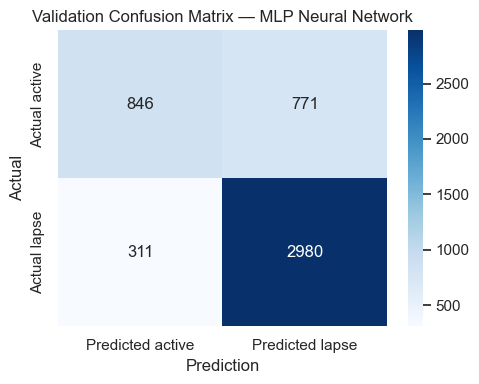

              precision    recall  f1-score   support

  Active (0)       0.73      0.52      0.61      1617
   Lapse (1)       0.79      0.91      0.85      3291

    accuracy                           0.78      4908
   macro avg       0.76      0.71      0.73      4908
weighted avg       0.77      0.78      0.77      4908



In [19]:
SELECTED_THRESHOLD = 0.50
print("Selected threshold:", SELECTED_THRESHOLD)

selected_threshold_metrics = evaluate_model( best_model, X_valid, y_valid, threshold=SELECTED_THRESHOLD )
display(pd.DataFrame([selected_threshold_metrics]))

valid_probabilities = get_positive_probability( best_model, X_valid )
plot_confusion( y_valid, valid_probabilities, threshold=SELECTED_THRESHOLD, title=f"Validation Confusion Matrix — {best_model_name}" )

## 7. Final evaluation on the test set

Final test metrics — MLP Neural Network


,accuracy,precision,recall,f1,roc_auc,threshold
0,0.720712,0.690221,0.92838,0.79178,0.795507,0.5


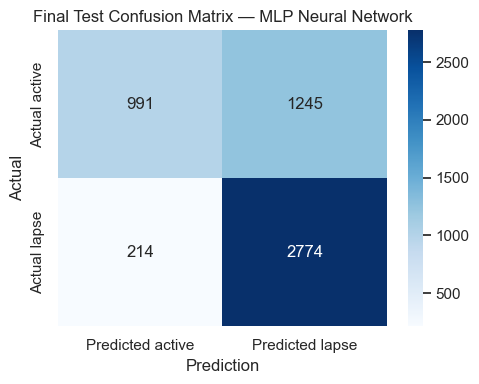

              precision    recall  f1-score   support

  Active (0)       0.82      0.44      0.58      2236
   Lapse (1)       0.69      0.93      0.79      2988

    accuracy                           0.72      5224
   macro avg       0.76      0.69      0.68      5224
weighted avg       0.75      0.72      0.70      5224

Saved final test metrics.


In [20]:
test_probabilities = get_positive_probability(best_model, X_test)
test_metrics = evaluate_model(best_model, X_test, y_test, threshold=SELECTED_THRESHOLD)
print("Final test metrics —", best_model_name)
display(pd.DataFrame([test_metrics]))
plot_confusion(y_test, test_probabilities, threshold=SELECTED_THRESHOLD,
               title=f"Final Test Confusion Matrix — {best_model_name}")

with mlflow.start_run(run_name=f"final-test-evaluation-{best_model_name}"):
    mlflow.log_param("selected_model", best_model_name)
    mlflow.log_param("threshold_from_validation", SELECTED_THRESHOLD)
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in test_metrics.items()})
    mlflow.set_tag("note", "Final evaluation only; test labels were not used for selection")

pd.DataFrame([{"model": best_model_name, **test_metrics}]).to_csv(
    OUTPUT_DIR / "final_test_metrics.csv", index=False
)
print("Saved final test metrics.")

## 8. SHAP explanations

C:\Users\kholi\AppData\Local\Temp\ipykernel_100\3795719905.py:33: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values_to_plot, X_shap, feature_names=feature_names, show=True)


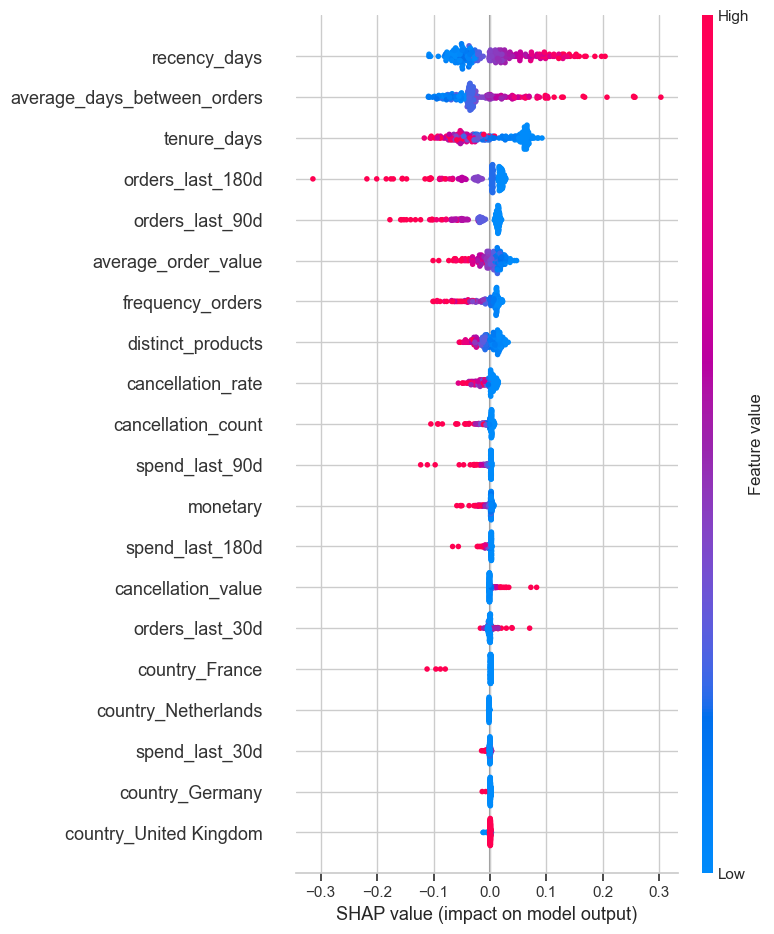

Explained validation row position in SHAP sample: 0
Predicted lapse probability: 0.0257


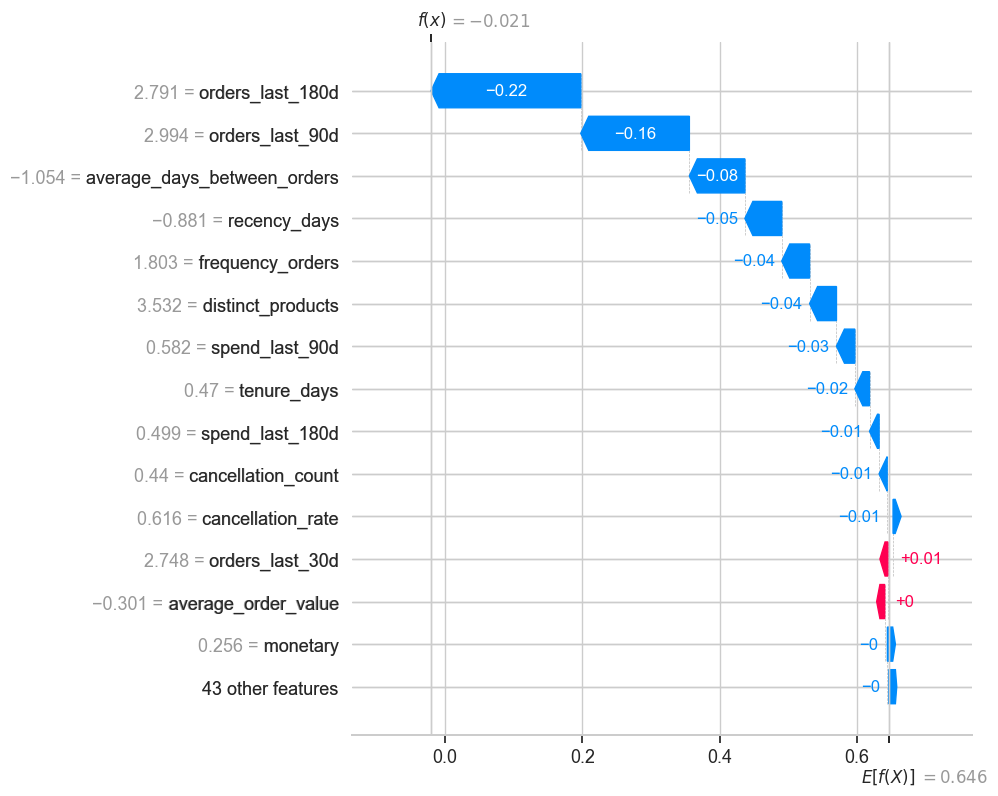

In [21]:
try:
    import shap
    
    fitted_preprocessor = best_model.named_steps["preprocessor"]
    fitted_estimator = best_model.named_steps["model"]
    feature_names = fitted_preprocessor.get_feature_names_out()
    X_valid_transformed = fitted_preprocessor.transform(X_valid)
    X_valid_explain = np.asarray(X_valid_transformed)

    sample_size = min(250, len(X_valid_explain))
    rng = np.random.default_rng(RANDOM_SEED)
    sample_indices = rng.choice(len(X_valid_explain), size=sample_size, replace=False)
    X_shap = X_valid_explain[sample_indices]

    if isinstance(fitted_estimator, (RandomForestClassifier, GradientBoostingClassifier)):
        explainer = shap.TreeExplainer(fitted_estimator)
        shap_values = explainer.shap_values(X_shap)
        if isinstance(shap_values, list):
            shap_values_to_plot = shap_values[1] if len(shap_values) > 1 else shap_values[0]
        elif np.asarray(shap_values).ndim == 3:
            shap_values_to_plot = np.asarray(shap_values)[:, :, 1]
        else:
            shap_values_to_plot = shap_values
    else:
        background_size = min(50, len(X_valid_explain))
        background_indices = rng.choice(len(X_valid_explain), size=background_size, replace=False)
        background = X_valid_explain[background_indices]
        explainer = shap.Explainer(fitted_estimator.predict_proba, background)
        shap_values = explainer(X_shap)
        vals = shap_values.values
        shap_values_to_plot = vals[:, :, 1] if vals.ndim == 3 else vals

    shap.summary_plot(shap_values_to_plot, X_shap, feature_names=feature_names, show=True)

    row_position = 0
    one_row = X_shap[row_position:row_position + 1]
    print("Explained validation row position in SHAP sample:", row_position)
    print("Predicted lapse probability:", round(float(best_model.predict_proba(
        X_valid.iloc[[int(sample_indices[row_position])]])[0, 1]), 4))
    shap.plots.waterfall(shap.Explanation(
        values=np.asarray(shap_values_to_plot)[row_position],
        base_values=float(np.mean(best_model.predict_proba(X_valid)[:, 1])),
        data=one_row[0], feature_names=feature_names
    ), max_display=15)
except Exception as e:
    print("SHAP explanation could not run:", repr(e))
    print("Install/update shap if needed: %pip install -U shap")

## 9. Save the selected model and produce the predictions table

In [22]:
MODEL_PATH = OUTPUT_DIR / "selected_customer_lapse_model.joblib"
joblib.dump(best_model, MODEL_PATH)

metadata = {
    "selected_model": best_model_name,
    "selection_metric": "validation ROC-AUC",
    "validation_roc_auc": float(validation_results_df.iloc[0]["roc_auc"]),
    "risk_threshold": float(SELECTED_THRESHOLD),
    "target_definition": "lapse=1 means no purchase in the following 90 days",
    "features": FEATURE_COLUMNS,
    "excluded_inputs": EXCLUDED_COLUMNS,
    "training_policy": "fit on lapse_train_v1 only; validation for selection; test for final evaluation",
}
with open(OUTPUT_DIR / "model_metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

def risk_category(probability, threshold=SELECTED_THRESHOLD):
    if probability >= threshold:
        return "High"
    if probability >= threshold * 0.60:
        return "Medium"
    return "Low"

predictions_df = pd.DataFrame({
    "customer_id": test_df["customer_id"].astype("string"),
    "snapshot_date": test_df["snapshot_date"],
    "lapse_probability": test_probabilities,
})
predictions_df["risk_category"] = predictions_df["lapse_probability"].apply(risk_category)

PREDICTIONS_PATH = OUTPUT_DIR / "customer_lapse_predictions.csv"
predictions_df.to_csv(PREDICTIONS_PATH, index=False)

evaluation_predictions = predictions_df.copy()
evaluation_predictions["actual_lapse"] = y_test.to_numpy()
evaluation_predictions.to_csv(OUTPUT_DIR / "customer_lapse_predictions_with_labels_for_evaluation_only.csv", index=False)

print("Saved model:", MODEL_PATH)
print("Saved metadata:", OUTPUT_DIR / "model_metadata.json")
print("Saved handoff predictions:", PREDICTIONS_PATH)
display(predictions_df.head(10))
display(predictions_df["risk_category"].value_counts().rename_axis("risk_category").to_frame("customers"))

Saved model: C:\Users\kholi\SIC-Graduation-project-\customer_lapse_outputs\selected_customer_lapse_model.joblib
Saved metadata: C:\Users\kholi\SIC-Graduation-project-\customer_lapse_outputs\model_metadata.json
Saved handoff predictions: C:\Users\kholi\SIC-Graduation-project-\customer_lapse_outputs\customer_lapse_predictions.csv


,customer_id,snapshot_date,lapse_probability,risk_category
0,12346,2011-09-01,0.887431,High
1,12347,2011-09-01,0.228189,Low
2,12348,2011-09-01,0.577762,High
3,12349,2011-09-01,0.790109,High
4,12350,2011-09-01,0.845353,High
5,12351,2011-09-01,0.865853,High
6,12352,2011-09-01,0.676966,High
7,12353,2011-09-01,0.813567,High
8,12354,2011-09-01,0.664945,High
9,12355,2011-09-01,0.891236,High


,customers
risk_category,
High,4019
Low,657
Medium,548
